In [1]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
pip install nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from pathlib import Path

In [6]:
import pandas as pd

In [7]:
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv(r'C:\Users\LENOVO\OneDrive - BUU\Meetings\Python\Medical Insurance Cost.csv')
print(df)

      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]


In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------------------------------------
# 0. ตั้งค่า path และโหลดข้อมูล
# -------------------------------------------------------------------------
# โฟลเดอร์หลักของโครงงาน
ROOT = Path(r"C:\Users\LENOVO\Downloads\Python")

# กำหนดที่อยู่ไฟล์ CSV
DATA = ROOT / "Medical Insurance Cost.csv"

TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# โหลดข้อมูลจากไฟล์ CSV
df = pd.read_csv(DATA)
print(f"โหลดข้อมูล {len(df)} แถว {df.shape[1]} คอลัมน์")
print(f"ค่าใช้จ่ายต่ำสุด-สูงสุด: {df['charges'].min():,.0f} - {df['charges'].max():,.0f}")

# -------------------------------------------------------------------------
# จัดกลุ่มข้อมูลและกำหนดลำดับตัวแปร
# -------------------------------------------------------------------------
# จัดกลุ่มภูมิภาค (Region)
TOP_REGIONS = ["southeast", "southwest", "northwest", "northeast"]
df["region_group"] = df["region"].where(df["region"].isin(TOP_REGIONS), "Other")

# เรียงลำดับหมวดหมู่ให้อ่านง่าย
ORDER_SEX = ["female", "male"]
ORDER_SMOKER = ["no", "yes"]
ORDER_REGION = ["southeast", "southwest", "northwest", "northeast"]

# จัดรูปแบบข้อความในคอลัมน์ให้อยู่ในรูปแบบมาตรฐาน (ตัวพิมพ์เล็ก ทั้งหมด)
key = df["region"].str.strip().str.lower()
canon = df.groupby(key)["region"].agg(lambda s: s.value_counts().index[0])
df["region_std"] = key.map(canon)

# ตั้งค่าธีมและสไตล์ของ กราฟ Matplotlib
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3
})

BLUE, ORANGE = "#2f6db5", "#e07b39"

def save(name):
    """บันทึกกราฟลง results/figures แล้วแสดงในโน้ตบุ๊ก"""
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150)
    plt.show()
    print("บันทึกกราฟ:", name)

โหลดข้อมูล 1338 แถว 7 คอลัมน์
ค่าใช้จ่ายต่ำสุด-สูงสุด: 1,122 - 63,770


In [10]:
# ===================================================
# สถิติเชิงพรรณนา (Descriptive Statistics)
# ===================================================

# 1.1 ตัวแปรเชิงปริมาณ: จำนวน ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ควอไทล์
num_cols = ["age", "bmi", "children", "charges"]
desc = df[num_cols].describe().T
desc["missing"] = df[num_cols].isna().sum()
desc = desc.round(1)
desc.to_csv(TAB / "descriptive_numeric.csv")

print("สถิติเชิงพรรณนา (ตัวแปรเชิงปริมาณ)")
display(desc)


# 1.2 ตัวแปรเชิงกลุ่ม: ความถี่และร้อยละ
cat_cols = ["sex", "smoker", "region_group"]
freq = []

for c in cat_cols:
    t = df[c].value_counts(dropna=False).rename_axis("category").reset_index(name="n")
    t["percent"] = (t["n"] / len(df) * 100).round(1)
    t.insert(0, "variable", c)
    freq.append(t)

freq = pd.concat(freq, ignore_index=True)
freq.to_csv(TAB / "frequency_categorical.csv", index=False)

print("\nความถี่ของตัวแปรเชิงกลุ่ม")
display(freq)

สถิติเชิงพรรณนา (ตัวแปรเชิงปริมาณ)


,count,mean,std,min,25%,50%,75%,max,missing
age,1338.0,39.2,14.0,18.0,27.0,39.0,51.0,64.0,0
bmi,1338.0,30.7,6.1,16.0,26.3,30.4,34.7,53.1,0
children,1338.0,1.1,1.2,0.0,0.0,1.0,2.0,5.0,0
charges,1338.0,13270.4,12110.0,1121.9,4740.3,9382.0,16639.9,63770.4,0



ความถี่ของตัวแปรเชิงกลุ่ม


,variable,category,n,percent
0,sex,male,676,50.5
1,sex,female,662,49.5
2,smoker,no,1064,79.5
3,smoker,yes,274,20.5
4,region_group,southeast,364,27.2
5,region_group,southwest,325,24.3
6,region_group,northwest,325,24.3
7,region_group,northeast,324,24.2


In [11]:
# =========================================================================
# ค่าใช้จ่ายประกันสุขภาพแยกตามกลุ่ม: n, ค่าเฉลี่ย, มัธยฐาน, SD, Q1, Q3
# =========================================================================

def charges_by(col, order=None):
    g = df.groupby(col)["charges"]
    out = pd.DataFrame({
        "n": g.size(), 
        "mean": g.mean(), 
        "median": g.median(), 
        "sd": g.std(),
        "q1": g.quantile(0.25), 
        "q3": g.quantile(0.75)
    }).round(1)
    if order:
        out = out.reindex([o for o in order if o in out.index])
    return out

# กำหนดตารางการจัดกลุ่มตามตัวแปรเชิงกลุ่มต่างๆ ในชุดข้อมูล
group_tables = {
    "sex": charges_by("sex", ORDER_SEX),
    "smoker": charges_by("smoker", ORDER_SMOKER),
    "region_group": charges_by("region_group", ORDER_REGION),
}

# บันทึกเป็นไฟล์ CSV และแสดงผลตาราง
for name, t in group_tables.items():
    t.to_csv(TAB / f"charges_by_{name}.csv")
    print(f"--- ค่าใช้จ่ายประกันสุขภาพแยกตาม {name} ---")
    display(t)
    print()

--- ค่าใช้จ่ายประกันสุขภาพแยกตาม sex ---


,n,mean,median,sd,q1,q3
sex,,,,,,
female,662,12569.6,9413.0,11128.7,4885.2,14454.7
male,676,13956.8,9369.6,12971.0,4619.1,18989.6



--- ค่าใช้จ่ายประกันสุขภาพแยกตาม smoker ---


,n,mean,median,sd,q1,q3
smoker,,,,,,
no,1064,8434.3,7345.4,5993.8,3986.4,11362.9
yes,274,32050.2,34456.3,11541.5,20826.2,41019.2



--- ค่าใช้จ่ายประกันสุขภาพแยกตาม region_group ---


,n,mean,median,sd,q1,q3
region_group,,,,,,
southeast,364,14735.4,9294.1,13971.1,4440.9,19526.3
southwest,325,12346.9,8798.6,11557.2,4751.1,13462.5
northwest,325,12417.6,8965.8,11072.3,4719.7,14711.7
northeast,324,13406.4,10057.7,11255.8,5194.3,16687.4


In [12]:
# ==============================================================================
# ข้อที่ 1.1: คำนวณค่าสถิติเชิงพรรณนา (Descriptive Statistics)
# ==============================================================================

# 1. กำหนดโครงสร้างโฟลเดอร์สำหรับบันทึกไฟล์ผลลัพธ์
TAB = Path("tables")
FIG = Path("figures")
TAB.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

# 2. คำนวณค่าสถิติตามกลุ่มที่กำหนด
stats_q1 = (
    df.groupby(["children", "smoker", "sex"], observed=False)["charges"]
    .agg(mean="mean", median="median", std="std", count="count")
    .reset_index()
)

# 3. แทนที่ค่า NaN ในคอลัมน์ std ด้วย 0 ให้ตารางสมบูรณ์
stats_q1["std"] = stats_q1["std"].fillna(0)

# 4. บันทึกตารางสถิติตัวเลขลงไฟล์ CSV
stats_q1.to_csv(TAB / "q1_female_male_charges_by_children_smoker.csv", index=False)
print("บันทึกตาราง: tables/q1_female_male_charges_by_children_smoker.csvv")

# 5. แสดงผลตารางสถิติทั้งหมดบนหน้าจอ (โชว์ครบทุกแถว)
print("=== สถิติข้อที่ 1: ค่าเบี้ยประกันสุขภาพเฉลี่ย จำแนกตามจำนวนลูก พฤติกรรมการสูบบุหรี่ และเพศ ===")
display(stats_q1)

บันทึกตาราง: tables/q1_female_male_charges_by_children_smoker.csvv
=== สถิติข้อที่ 1: ค่าเบี้ยประกันสุขภาพเฉลี่ย จำแนกตามจำนวนลูก พฤติกรรมการสูบบุหรี่ และเพศ ===


,children,smoker,sex,mean,median,std,count
0,0,no,female,7688.318863,5915.524050,5675.058181,236
1,0,no,male,7530.806677,6358.776450,6058.394926,223
2,0,yes,female,30685.059887,29330.983150,11965.264660,53
3,0,yes,male,31902.398075,34644.993925,11339.760493,62
4,1,no,female,8758.560884,7337.748000,6434.007817,133
5,1,no,male,7837.147396,6756.855975,5478.252966,130
6,1,yes,female,30264.253915,23401.305750,12989.107927,25
7,1,yes,male,32904.876848,37926.560485,10981.481208,36
8,2,no,female,9921.777645,8520.026000,6391.530503,97
9,2,no,male,9020.567024,7160.212150,6530.338063,88


บันทึกรูปภาพ: figures/q1_charges_grouped_barchart_all.png


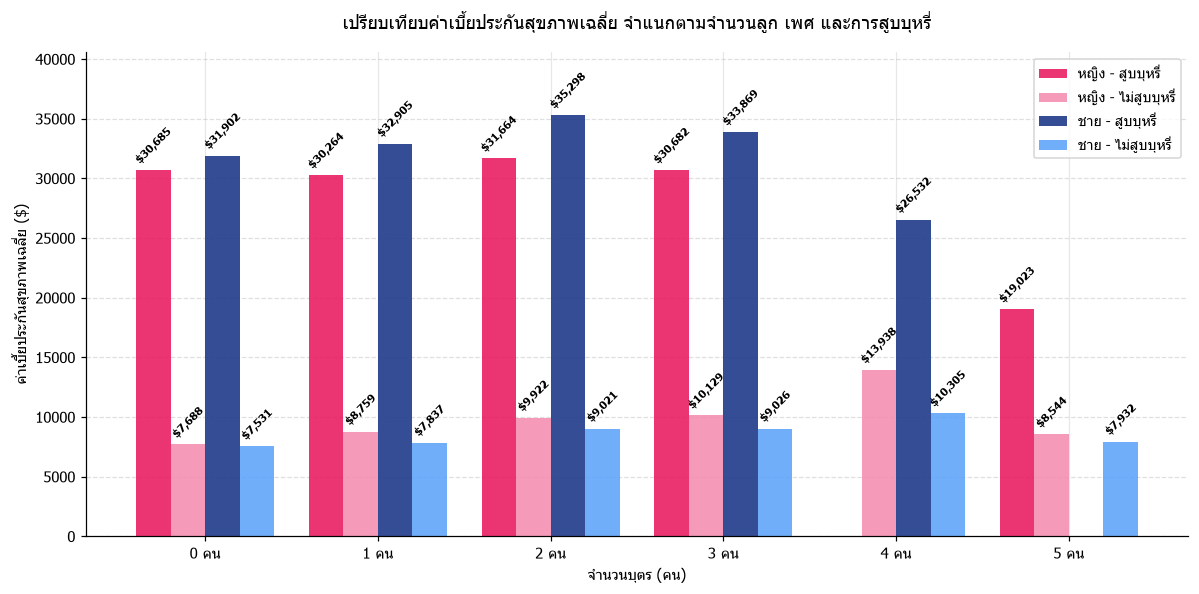

In [13]:
# ==============================================================================
# ข้อที่ 1.2: วาดกราฟแท่งแบบจัดกลุ่ม (Grouped Bar Chart)
# ==============================================================================
# 1. กำหนดฟอนต์ไทยและการแสดงผลเครื่องหมายลบ
plt.rcParams["font.family"] = "Tahoma"
plt.rcParams["axes.unicode_minus"] = False

# 2. เตรียมข้อมูลแกน X (จำนวนลูก)
children_list = sorted(df["children"].unique())
children_labels = [f"{c} คน" for c in children_list]

# 3. แปลงข้อมูลตารางเป็น Pivot Table
df_pivot = stats_q1.pivot(
    index="children", columns=["sex", "smoker"], values="mean"
).reindex(children_list)

# 4. กำหนดตำแหน่งบนแกน X
x = np.arange(len(children_labels))
width = 0.2

# 5. สร้างผืนผ้าใบสำหรับวาดกราฟ
plt.figure(figsize=(11, 5.5))

# สเปกของแต่ละแท่งกราฟ (ระยะเยื้อง, ข้อมูล, ป้ายชื่อ, สี)
bars_spec = [
    (-1.5 * width, df_pivot[("female", "yes")], "หญิง - สูบบุหรี่", "#E91E63"),
    (-0.5 * width, df_pivot[("female", "no")], "หญิง - ไม่สูบบุหรี่", "#F48FB1"),
    (0.5 * width, df_pivot[("male", "yes")], "ชาย - สูบบุหรี่", "#1E3A8A"),
    (1.5 * width, df_pivot[("male", "no")], "ชาย - ไม่สูบบุหรี่", "#60A5FA"),
]

# 6. วาดแท่งกราฟและใส่ตัวเลขบนปลายแท่ง
for offset, data, label, color in bars_spec:
    data_filled = data.fillna(0)
    rects = plt.bar(x + offset, data_filled, width, label=label, color=color, alpha=0.9)
    for rect in rects:
        height = rect.get_height()
        if height > 0:
            plt.annotate(
                f"${height:,.0f}",
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=7,
                fontweight="bold",
                rotation=45,
            )

# 7. ปรับแต่งรายละเอียดและองค์ประกอบกราฟ
plt.title("เปรียบเทียบค่าเบี้ยประกันสุขภาพเฉลี่ย จำแนกตามจำนวนลูก เพศ และการสูบบุหรี่", fontsize=12, pad=15)
plt.xlabel("จำนวนบุตร (คน)", fontsize=10)
plt.ylabel("ค่าเบี้ยประกันสุขภาพเฉลี่ย ($)", fontsize=10)
plt.xticks(x, children_labels)
plt.legend(loc="upper right", frameon=True, fontsize=9)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.gca().set_axisbelow(True)

# ปรับขอบเขตแกน Y ด้วย np.nanmax เพื่อป้องกันข้อผิดพลาดกรณีมีค่า NaN
plt.ylim(0, np.nanmax(df_pivot.values) * 1.15)

# 8. บันทึกและแสดงผลรูปภาพ
plt.tight_layout()
plt.savefig(FIG / "q1_charges_grouped_barchart_all.png", dpi=300)
print("บันทึกรูปภาพ: figures/q1_charges_grouped_barchart_all.png")
plt.show()

In [14]:
# ==============================================================================
# ข้อที่ 2.1: คำนวณสถิติการกระจายตัว (Distribution Statistics)
# ==============================================================================

# 1. กรองข้อมูลเฉพาะกลุ่มผู้สูบบุหรี่
df_q2 = df[df["smoker"] == "yes"]

# 2. คำนวณค่าสถิติวัดการกระจายแยกตามภูมิภาคและเพศ
stats_q2 = (
    df_q2.groupby(["region", "sex"], observed=False)["charges"]
    .agg(
        count="count",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        min="min",
        max="max",
    )
    .reset_index()
)

# 3. คำนวณ IQR และ ขอบเขตรับค่าปกติ (Lower/Upper Bound)
stats_q2["iqr"] = stats_q2["q3"] - stats_q2["q1"]
stats_q2["lower_bound"] = stats_q2["q1"] - 1.5 * stats_q2["iqr"]
stats_q2["upper_bound"] = stats_q2["q3"] + 1.5 * stats_q2["iqr"]
stats_q2 = stats_q2.round(2)

# 4. บันทึกไฟล์ CSV และแสดงตาราง
stats_q2.to_csv(TAB / "q2_smoker_charges_by_region_sex.csv", index=False)
print("บันทึกตาราง: tables/q2_smoker_charges_by_region_sex.csv")
print("=== สถิติข้อที่ 2: การกระจายตัวของค่าเบี้ยประกันกลุ่มผู้สูบบุหรี่ (แยกตามภูมิภาคและเพศ) ===")
display(stats_q2)

บันทึกตาราง: tables/q2_smoker_charges_by_region_sex.csv
=== สถิติข้อที่ 2: การกระจายตัวของค่าเบี้ยประกันกลุ่มผู้สูบบุหรี่ (แยกตามภูมิภาคและเพศ) ===


,region,sex,count,median,q1,q3,min,max,iqr,lower_bound,upper_bound
0,northeast,female,29,22331.57,16776.30,38511.63,14283.46,58571.07,21735.32,-15826.68,71114.61
1,northeast,male,38,33993.37,21052.91,39587.18,12829.46,48549.18,18534.26,-6748.48,67388.58
2,northwest,female,29,28950.47,21348.71,39725.52,14711.74,55135.40,18376.81,-6216.51,67290.74
3,northwest,male,29,26109.33,20745.99,40720.55,15817.99,60021.40,19974.56,-9215.85,70682.39
4,southeast,female,36,35017.72,23199.95,41473.09,16577.78,63770.43,18273.14,-4209.76,68882.80
5,southeast,male,55,38282.75,24572.31,44008.26,17043.34,62592.87,19435.95,-4581.60,73162.18
6,southwest,female,21,34166.27,19023.26,41661.60,13844.51,48824.45,22638.34,-14934.25,75619.11
7,southwest,male,37,35585.58,22144.03,39241.44,15820.70,52590.83,17097.41,-3502.08,64887.56


บันทึกรูปภาพ: figures/q2_smoker_charges_boxplot.png


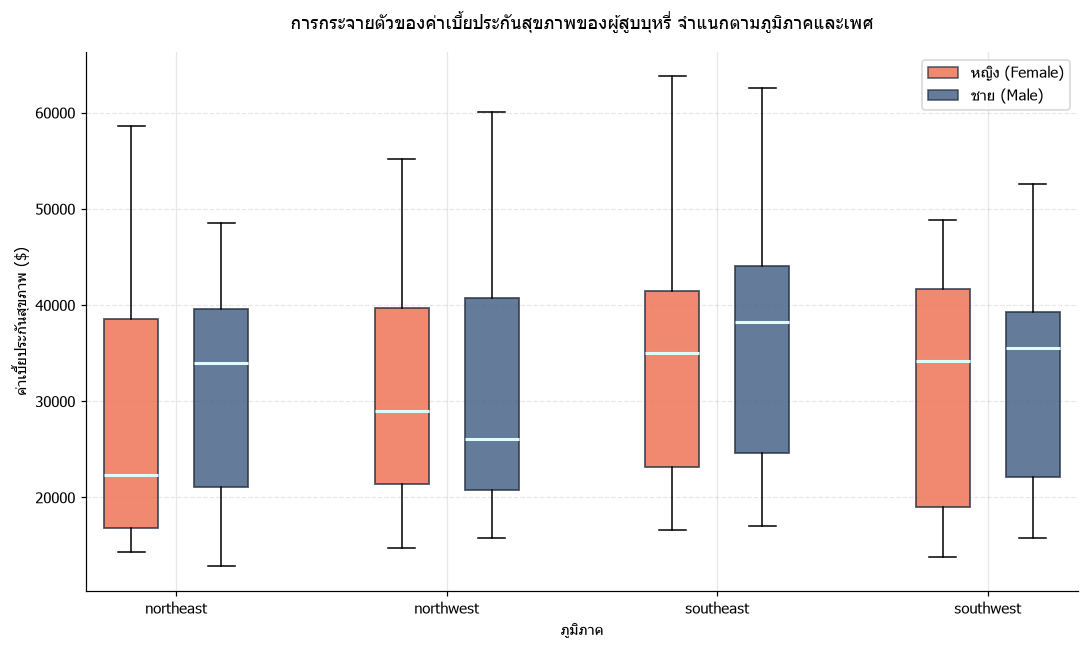

In [15]:
# ===================================================
# ข้อที่ 2.2: วาดแผนภาพกล่อง (Boxplot)
# ===================================================

from matplotlib.patches import Patch

# 1. กำหนดฟอนต์ไทย
plt.rcParams["font.family"] = "Tahoma"

# 2. จัดกลุ่มชุดข้อมูลและพิกัดลงใน List
regions = sorted(df_q2["region"].unique())
sexes = ["female", "male"]

data_to_plot = []
positions = []

pos = 1
for reg in regions:
    for sex in sexes:
        subset = df_q2[(df_q2["region"] == reg) & (df_q2["sex"] == sex)]["charges"]
        data_to_plot.append(subset)
        positions.append(pos)
        pos += 1
    pos += 1  # เว้นช่องว่างระหว่างแต่ละภูมิภาค

# 3. สร้างกราฟ Boxplot
plt.figure(figsize=(10, 6))
bp = plt.boxplot(data_to_plot, positions=positions, patch_artist=True, widths=0.6)

# 4. ตกแต่งสีสันกล่อง (Box Colors)
COLOR_FEMALE = "#EE6C4D"  # ส้มคอรัล
COLOR_MALE = "#3D5A80"    # น้ำเงินคราม
colors = [COLOR_FEMALE, COLOR_MALE] * len(regions)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
    patch.set_edgecolor("#293241")
    patch.set_linewidth(1.2)

# ตกแต่งเส้นมัธยฐาน
for median in bp["medians"]:
    median.set_color("#E0FBFC")
    median.set_linewidth(2)

# 5. กำหนดชื่อแกนและสัญลักษณ์ (Legend)
tick_pos = [i * 3 + 1.5 for i in range(len(regions))]
plt.xticks(tick_pos, regions)

legend_elements = [
    Patch(facecolor=COLOR_FEMALE, edgecolor="#293241", alpha=0.8, label="หญิง (Female)"),
    Patch(facecolor=COLOR_MALE, edgecolor="#293241", alpha=0.8, label="ชาย (Male)"),
]
plt.legend(handles=legend_elements, loc="upper right")

plt.title("การกระจายตัวของค่าเบี้ยประกันสุขภาพของผู้สูบบุหรี่ จำแนกตามภูมิภาคและเพศ", fontsize=12, pad=15)
plt.xlabel("ภูมิภาค", fontsize=10)
plt.ylabel("ค่าเบี้ยประกันสุขภาพ ($)", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.3)

# 6. บันทึกและแสดงผล
plt.tight_layout()
plt.savefig("figures/q2_smoker_charges_boxplot.png", dpi=300)
print("บันทึกรูปภาพ: figures/q2_smoker_charges_boxplot.png")
plt.show()

In [16]:
# ===================================================
# ข้อที่ 3.1: คำนวณ Correlation และ สัมประสิทธิ์ Polynomial Regression (Degree 2)
# ===================================================

import os
import numpy as np
import pandas as pd
from scipy import stats  # เพิ่มบรรทัดนี้เพื่อแก้ไขปัญหา NameError

# 0. สร้างโฟลเดอร์ tables อัตโนมัติหากยังไม่มี
os.makedirs("tables", exist_ok=True)

# 1. ดึงข้อมูลที่จำเป็น (ตัดค่าว่างออกหากมี)
df_q3 = df[["bmi", "charges", "smoker"]].dropna()

# 2. คำนวณ Pearson และ Spearman Correlation
r_pearson, p_pearson = stats.pearsonr(df_q3["bmi"], df_q3["charges"])
r_spearman, p_spearman = stats.spearmanr(df_q3["bmi"], df_q3["charges"])

# 3. คำนวณสัมประสิทธิ์สมการ Polynomial Regression ดีกรี 2 (b2*X^2 + b1*X + b0)
beta_2, beta_1, beta_0 = np.polyfit(df_q3["bmi"], df_q3["charges"], 2)

print("=== สมการ Polynomial Regression (Degree 2) ===")
print(f"y_hat = {beta_0:.2f} + ({beta_1:.2f})*X + ({beta_2:.2f})*X^2")

# 4. สรุปผลตาราง Correlation
corr_summary = pd.DataFrame(
    {
        "ประเภท Correlation": [
            "Pearson Correlation (r)",
            "Spearman Correlation (rho)",
        ],
        "ค่าสัมประสิทธิ์": [round(r_pearson, 4), round(r_spearman, 4)],
        "p-value": [f"{p_pearson:.4e}", f"{p_spearman:.4e}"],
    }
)

# 5. บันทึกผลคำนวณลงไฟล์ CSV
corr_summary.to_csv("tables/q3_bmi_charges_correlation.csv", index=False)
print("บันทึกตาราง: tables/q3_bmi_charges_correlation.csv")

print("\n--- สถิติข้อที่ 3: สัมประสิทธิ์สหสัมพันธ์ระหว่าง BMI กับเบี้ยประกัน ---")
display(corr_summary)

=== สมการ Polynomial Regression (Degree 2) ===
y_hat = -5177.03 + (813.97)*X + (-6.66)*X^2
บันทึกตาราง: tables/q3_bmi_charges_correlation.csv

--- สถิติข้อที่ 3: สัมประสิทธิ์สหสัมพันธ์ระหว่าง BMI กับเบี้ยประกัน ---


,ประเภท Correlation,ค่าสัมประสิทธิ์,p-value
0,Pearson Correlation (r),0.1983,2.4591e-13
1,Spearman Correlation (rho),0.1194,1.1926e-05


บันทึกรูปภาพ: figures/q3_bmi_vs_charges_polynomial.png


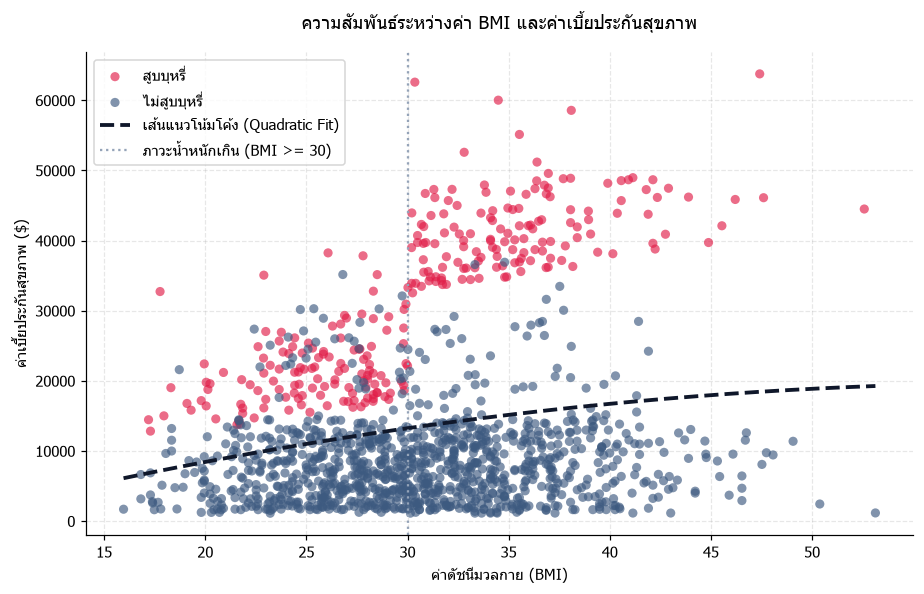

In [17]:
# ===================================================
# ข้อที่ 3.2: วาด Scatter Plot พร้อมเส้น Polynomial Trendline (Degree 2)
# ===================================================

# 1. สร้างโฟลเดอร์ figures อัตโนมัติหากยังไม่มี
os.makedirs("figures", exist_ok=True)

# 2. เตรียมข้อมูล df_q3 และคำนวณค่าสัมประสิทธิ์ beta
df_q3 = df[["bmi", "charges", "smoker"]].dropna()
beta_2, beta_1, beta_0 = np.polyfit(df_q3["bmi"], df_q3["charges"], 2)

# 3. ตั้งค่าฟอนต์ไทยและแยกข้อมูลกลุ่มผู้สูบบุหรี่
plt.rcParams["font.family"] = "Tahoma"

smoker_yes = df_q3[df_q3["smoker"] == "yes"]
smoker_no = df_q3[df_q3["smoker"] == "no"]

# 4. สร้างกราฟ Scatter Plot
plt.figure(figsize=(8.5, 5.5))
plt.scatter(
    smoker_yes["bmi"],
    smoker_yes["charges"],
    color="#E11D48",
    alpha=0.65,
    edgecolors="none",
    label="สูบบุหรี่",
)
plt.scatter(
    smoker_no["bmi"],
    smoker_no["charges"],
    color="#3D5A80",
    alpha=0.65,
    edgecolors="none",
    label="ไม่สูบบุหรี่",
)

# 5. สร้างเส้นโค้ง Polynomial Trendline (Degree 2)
x_line = np.linspace(df_q3["bmi"].min(), df_q3["bmi"].max(), 200)
y_line = beta_0 + beta_1 * x_line + beta_2 * (x_line**2)

plt.plot(
    x_line,
    y_line,
    color="#0F172A",
    linestyle="--",
    linewidth=2.5,
    label="เส้นแนวโน้มโค้ง (Quadratic Fit)",
)
plt.axvline(
    x=30,
    color="#94A3B8",
    linestyle=":",
    linewidth=1.5,
    label="ภาวะน้ำหนักเกิน (BMI >= 30)",
)

plt.title(
    "ความสัมพันธ์ระหว่างค่า BMI และค่าเบี้ยประกันสุขภาพ",
    fontsize=12,
    pad=15,
)
plt.xlabel("ค่าดัชนีมวลกาย (BMI)", fontsize=10)
plt.ylabel("ค่าเบี้ยประกันสุขภาพ ($)", fontsize=10)
plt.legend(loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()

# 6. บันทึกรูปภาพลงโฟลเดอร์ figures และแสดงผล
plt.savefig("figures/q3_bmi_vs_charges_polynomial.png", dpi=300)
print("บันทึกรูปภาพ: figures/q3_bmi_vs_charges_polynomial.png")
plt.show()

In [20]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# สร้างโฟลเดอร์ tables สำหรับบันทึกไฟล์ CSV อัตโนมัติหากยังไม่มี
os.makedirs("tables", exist_ok=True)

# 1. เลือกตัวแปรทั้งหมด (รวม smoker, sex, region)
features = ["age", "bmi", "children", "smoker", "sex", "region"]

# แปลงตัวแปร Categorical (กลุ่ม) เป็น ตัวเลข (Dummy variables)
X = pd.get_dummies(df[features], drop_first=True)
y = df["charges"]

# 2. แบ่งข้อมูล Train (80%) และ Test (20%) ตามมาตรฐาน
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"ชุดฝึก {len(X_train)} แถว | ชุดทดสอบ {len(X_test)} แถว")

# 3. สร้างโมเดล Linear Regression
model = LinearRegression()

# 4. fit เฉพาะ Train Set
model.fit(X_train, y_train)


# 5. ฟังก์ชันวัดผล R², MAE, RMSE
def metrics(X_, y_, name):
    p = model.predict(X_)
    return {
        "dataset": name,
        "n": len(y_),
        "MAE (USD)": round(mean_absolute_error(y_, p), 2),
        "RMSE (USD)": round(np.sqrt(mean_squared_error(y_, p)), 2),
        "R2": round(r2_score(y_, p), 4),
    }


res = pd.DataFrame(
    [metrics(X_train, y_train, "Train"), metrics(X_test, y_test, "Test")]
)

# 6. บันทึกตารางลงไฟล์ CSV และแสดงผลลัพธ์
res.to_csv("tables/linear_model_metrics.csv", index=False)
print("บันทึกตาราง: tables/linear_model_metrics.csv")
print("\n--- ผลการประเมิน Multiple Linear Regression (หน่วยเงิน - ดอลลาร์) ---")
display(res)

ชุดฝึก 1070 แถว | ชุดทดสอบ 268 แถว
บันทึกตาราง: tables/linear_model_metrics.csv

--- ผลการประเมิน Multiple Linear Regression (หน่วยเงิน - ดอลลาร์) ---


,dataset,n,MAE (USD),RMSE (USD),R2
0,Train,1070,4208.23,6105.55,0.7417
1,Test,268,4181.19,5796.28,0.7836


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

# สร้างโฟลเดอร์ tables สำหรับบันทึกไฟล์ CSV อัตโนมัติหากยังไม่มี
os.makedirs("tables", exist_ok=True)

# 1. เลือกตัวแปรต้นทั้งหมด (รวม smoker, sex, region)
features = ["age", "bmi", "children", "smoker", "sex", "region"]

# แปลงตัวแปร Categorical (กลุ่ม) เป็น ตัวเลข (Dummy variables)
X = pd.get_dummies(df[features], drop_first=True)
y = df["charges"]

# 2. แบ่งข้อมูล Train (80%) และ Test (20%) ตามมาตรฐาน
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"ชุดฝึก {len(X_train)} แถว | ชุดทดสอบ {len(X_test)} แถว")

# 3. สร้าง Pipeline พหุนามดีกรี 2 + LinearRegression (ตรงตามบทเรียน)
model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False), LinearRegression()
)

# 4. fit เฉพาะ Train Set
model.fit(X_train, y_train)


# 5. ฟังก์ชันวัดผล R², MAE, RMSE
def metrics(X_, y_, name):
    p = model.predict(X_)
    return {
        "dataset": name,
        "n": len(y_),
        "MAE (USD)": round(mean_absolute_error(y_, p), 2),
        "RMSE (USD)": round(np.sqrt(mean_squared_error(y_, p)), 2),
        "R2": round(r2_score(y_, p), 4),
    }


res = pd.DataFrame(
    [metrics(X_train, y_train, "Train"), metrics(X_test, y_test, "Test")]
)

# 6. บันทึกตารางลงไฟล์ CSV และแสดงผลลัพธ์
res.to_csv("tables/polynomial_model_metrics.csv", index=False)
print("บันทึกตาราง: tables/polynomial_model_metrics.csv")
print("\n=== ผลการประเมิน Polynomial Regression (หน่วยเงิน = ดอลลาร์) ===")
display(res)

ชุดฝึก 1070 แถว | ชุดทดสอบ 268 แถว
บันทึกตาราง: tables/polynomial_model_metrics.csv

=== ผลการประเมิน Polynomial Regression (หน่วยเงิน = ดอลลาร์) ===


,dataset,n,MAE (USD),RMSE (USD),R2
0,Train,1070,2892.15,4778.19,0.8418
1,Test,268,2729.50,4551.13,0.8666


บันทึกรูปภาพ: figures/model_comparison_scatter.png


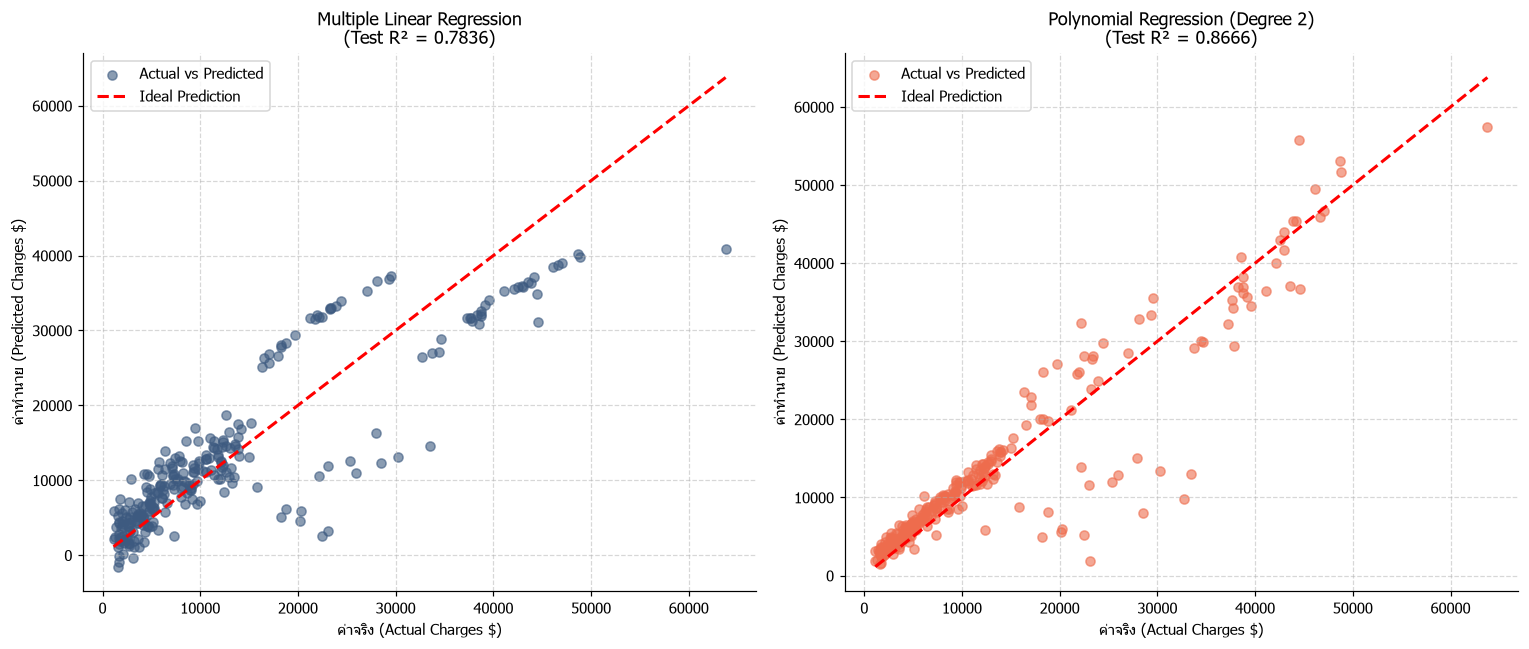

In [21]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

# 0. กำหนดฟอนต์ภาษาไทยและโฟลเดอร์
os.makedirs("figures", exist_ok=True)
plt.rcParams["font.family"] = "Tahoma"

# 1. เตรียมข้อมูล
features = ["age", "bmi", "children", "smoker", "sex", "region"]
X = pd.get_dummies(df[features], drop_first=True)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. สร้างและ fit โมเดลทั้ง 2 รูปแบบ
# 2.1 Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
r2_linear = r2_score(y_test, y_pred_linear)

# 2.2 Polynomial Regression (Degree 2)
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False), LinearRegression()
)
poly_model.fit(X_train, y_train)
y_pred_poly = poly_model.predict(X_test)
r2_poly = r2_score(y_test, y_pred_poly)

# 3. วาดกราฟเปรียบเทียบ
plt.figure(figsize=(14, 6))

# Subplot 1: Linear Regression
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_linear, alpha=0.6, color="#3D5A80", label="Actual vs Predicted")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
    label="Ideal Prediction",
)
plt.title(f"Multiple Linear Regression\n(Test R² = {r2_linear:.4f})", fontsize=12)
plt.xlabel("ค่าจริง (Actual Charges $)", fontsize=10)
plt.ylabel("ค่าทำนาย (Predicted Charges $)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

# Subplot 2: Polynomial Regression
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_poly, alpha=0.6, color="#EE6C4D", label="Actual vs Predicted")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
    label="Ideal Prediction",
)
plt.title(f"Polynomial Regression (Degree 2)\n(Test R² = {r2_poly:.4f})", fontsize=12)
plt.xlabel("ค่าจริง (Actual Charges $)", fontsize=10)
plt.ylabel("ค่าทำนาย (Predicted Charges $)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

# 4. บันทึกและแสดงผล
plt.tight_layout()
plt.savefig("figures/model_comparison_scatter.png", dpi=300)
print("บันทึกรูปภาพ: figures/model_comparison_scatter.png")
plt.show()

In [25]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

# 1. เตรียมข้อมูล
features = ["age", "bmi", "children", "smoker", "sex", "region"]
X = pd.get_dummies(df[features], drop_first=True)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# 1. Multiple Linear Regression Equation
# ==========================================
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

intercept_lin = linear_model.intercept_
coefs_lin = linear_model.coef_

lin_eq = f"charges_hat = {intercept_lin:.2f}"
for coef, name in zip(coefs_lin, X.columns):
    sign = "+" if coef >= 0 else "-"
    lin_eq += f" {sign} {abs(coef):.2f}*({name})"

print("=== 1. สมการ Multiple Linear Regression ===")
print(lin_eq)


# ==========================================
# 2. Polynomial Regression Equation (เฉพาะ BMI กับ BMI^2)
# ==========================================
# สร้างโมเดลพหุนามระดับ 2 เฉพาะ BMI เพื่อให้สมการกระชับ นำไปใช้อธิบายในสไลด์ได้ง่าย
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_bmi_poly = poly_features.fit_transform(X_train[["bmi"]])

poly_model = LinearRegression()
poly_model.fit(X_bmi_poly, y_train)

intercept_poly = poly_model.intercept_
coefs_poly = poly_model.coef_

poly_eq = (
    f"charges_hat = {intercept_poly:.2f} "
    f"+ ({coefs_poly[0]:.2f})*BMI "
    f"+ ({coefs_poly[1]:.2f})*BMI^2"
)

print("\n=== 2. สมการ Polynomial Regression (BMI) ===")
print(poly_eq)

=== 1. สมการ Multiple Linear Regression ===
charges_hat = -11931.22 + 256.98*(age) + 337.09*(bmi) + 425.28*(children) + 23651.13*(smoker_yes) - 18.59*(sex_male) - 370.68*(region_northwest) - 657.86*(region_southeast) - 809.80*(region_southwest)

=== 2. สมการ Polynomial Regression (BMI) ===
charges_hat = -10555.63 + (1181.28)*BMI + (-12.57)*BMI^2
